# Assignment: Limit Order Book — Basics to Intermediate

**Reference material:** [An Introduction to Limit Order Books — machow.ski](https://www.machow.ski/posts/2021-07-18-introduction-to-limit-order-books/)

---

### What is this assignment about?

Every time someone buys or sells a stock (or crypto), their order goes into a **Limit Order Book (LOB)**. The LOB is the engine at the heart of every exchange — it keeps track of who wants to buy, who wants to sell, at what prices, and matches them together.

In this assignment, you will **build a working LOB step by step**, starting from very simple ideas and slowly adding more complexity.

### How to attempt this
- Read each section carefully — there is a concept explanation before every coding task.
- Look at the **Hint** boxes — they guide you without giving the answer away.
- Fill in every cell that says `# YOUR CODE HERE`.
- Run the test cells after each question to check your work.

### Marks
| Section | Topic | Marks |
|---------|-------|-------|
| 1 | Representing a Single Order | 15 |
| 2 | Building the Order Book | 25 |
| 3 | Executing Trades (Matching) | 25 |
| 4 | Market Metrics | 20 |
| 5 | Thinking Like a Trader | 15 |
| **Total** | | **100** |

---

## Section 1 — Representing a Single Order (15 marks)

### Concept: What is an Order?

When you walk into a market and say *"I want to buy 100 shares of AAPL at $150"*, that is an **order**. Every order has four pieces of information:

| Field | Meaning | Example |
|-------|---------|--------|
| `side` | Are you buying or selling? | `'BID'` (buy) or `'ASK'` (sell) |
| `quantity` | How many shares? | `100` |
| `price` | At what price? | `150.0` |
| `order_id` | A unique name for this order | `'order_1'` |

We will represent an order as a **Python dictionary** — a collection of key-value pairs.

---
### Python Concept: Dictionaries

A **dictionary** stores information as `key: value` pairs, like a real dictionary stores `word: definition`.

```python
# Creating a dictionary
person = {
    'name': 'Alice',
    'age': 25
}

# Reading a value
print(person['name'])   # prints: Alice

# Changing a value
person['age'] = 26
```

We will use dictionaries to store orders because each order has several named fields.

### Q1.1 — Write a function that creates an order (5 marks)

Write a function `create_order(order_id, side, quantity, price)` that returns a dictionary representing an order.

The dictionary must have these keys: `'order_id'`, `'side'`, `'quantity'`, `'price'`, and also `'filled_qty'` which starts at `0` (how much of the order has been traded so far).

> **Hint:** Return a dict `{}` with all five keys. `filled_qty` is always `0` when a new order is created — nothing has been traded yet.

In [1]:
def create_order(order_id, side, quantity, price):
    """
    Creates and returns a new order as a dictionary.

    Parameters:
        order_id  : a unique string name for this order, e.g. 'order_1'
        side      : 'BID' (want to buy) or 'ASK' (want to sell)
        quantity  : number of shares
        price     : limit price (float)

    Returns:
        A dictionary with keys: order_id, side, quantity, price, filled_qty
    """
    return {
        'order_id': order_id,
        'side': side,
        'quantity': quantity,
        'price': price,
        'filled_qty': 0
    }

In [2]:
# TEST — run this cell to check your answer
o = create_order('order_1', 'BID', 100, 150.0)
assert o['order_id']  == 'order_1',  "order_id should be 'order_1'"
assert o['side']      == 'BID',      "side should be 'BID'"
assert o['quantity']  == 100,        "quantity should be 100"
assert o['price']     == 150.0,      "price should be 150.0"
assert o['filled_qty']== 0,          "filled_qty should start at 0"
print('Q1.1 ✓ Passed!')

Q1.1 ✓ Passed!


### Q1.2 — Remaining quantity (5 marks)

Once an order is partially filled, we need to know how much is **still left to trade**. This is called the **remaining quantity**.

$$\text{remaining\_qty} = \text{quantity} - \text{filled\_qty}$$

Write a function `remaining_qty(order)` that takes an order dictionary and returns the remaining quantity.

> **Hint:** Access `order['quantity']` and `order['filled_qty']` and subtract them.

In [3]:
def remaining_qty(order):
    """
    Returns how many shares of this order have NOT yet been filled.
    """
    return order['quantity'] - order['filled_qty']

In [4]:
# TEST
o = create_order('o1', 'ASK', 500, 101.0)
assert remaining_qty(o) == 500, "Fresh order: remaining should equal total quantity"
o['filled_qty'] = 200
assert remaining_qty(o) == 300, "After partial fill: remaining should be 500 - 200 = 300"
print('Q1.2 ✓ Passed!')

Q1.2 ✓ Passed!


### Q1.3 — Display an order nicely (5 marks)

Write a function `display_order(order)` that **prints** the order in a readable format.

Example output (for a BID order for 100 shares at $150, with 40 filled):
```
[BID] order_1 | Price: $150.0 | Qty: 100 | Filled: 40 | Remaining: 60
```

> **Hint:** Use an **f-string** to format the output: `f"[{order['side']}] ..."`
>
> An f-string lets you embed variables directly inside a string: `f"Hello {name}"` prints `Hello Alice` if `name = 'Alice'`.

In [5]:
def display_order(order):
    """
    Prints a human-readable summary of the order.
    """
    rem = remaining_qty(order)
    print(f"[{order['side']}] {order['order_id']} | Price: ${order['price']} | Qty: {order['quantity']} | Filled: {order['filled_qty']} | Remaining: {rem}")

# Try it out:
sample = create_order('order_1', 'BID', 100, 150.0)
sample['filled_qty'] = 40
display_order(sample)

[BID] order_1 | Price: $150.0 | Qty: 100 | Filled: 40 | Remaining: 60


---
## Section 2 — Building the Order Book (25 marks)

### Concept: What is an Order Book?

An order book is simply a **big organised list** of all the orders that haven't been traded yet. It has two sides:

- **Bid side** — all the buy orders. Sorted so the **highest price** is at the top (best bid).
- **Ask side** — all the sell orders. Sorted so the **lowest price** is at the top (best ask).

Here's what a simple book looks like:

```
BIDS (Buyers)          ASKS (Sellers)
--------------         ---------------
Price  | Qty           Price  | Qty
  99   | 800    <---best bid      101  | 1000  <--- best ask
  98   | 500              102  | 500
  97   | 1000             103  | 200
```

The gap between the best bid ($99) and the best ask ($101) is called the **spread** ($2 here).

---
### Python Concept: Classes

A **class** is a blueprint for creating objects that bundle together data and functions.

```python
class Dog:
    def __init__(self, name, breed):   # __init__ runs when you create a Dog
        self.name  = name              # self.name stores the name inside the object
        self.breed = breed

    def bark(self):                    # a method (function inside the class)
        print(f"{self.name} says: Woof!")

# Creating an object from the class
my_dog = Dog('Rex', 'Labrador')
my_dog.bark()   # prints: Rex says: Woof!
```

We will use a class called `OrderBook` to represent our order book, because it has both **data** (the lists of orders) and **actions** (add order, cancel order, etc.).

`self` always refers to the specific object you are working with.

### Q2.1 — Create the `OrderBook` class with `__init__` (5 marks)

Create a class `OrderBook`. In `__init__`, it should set up:
- `self.bids` — an **empty list** that will hold all buy orders
- `self.asks` — an **empty list** that will hold all sell orders
- `self.trade_log` — an **empty list** that will record every trade that happens

> 💡 **Hint:** Inside `__init__`, write `self.bids = []` and so on for each attribute.

In [6]:
class OrderBook:
    """
    Represents a Limit Order Book.
    Keeps track of all resting buy and sell orders.
    """

    def __init__(self):
        self.bids = []
        self.asks = []
        self.trade_log = []

In [7]:
# TEST
lob = OrderBook()
assert lob.bids      == [], "bids should start as empty list"
assert lob.asks      == [], "asks should start as empty list"
assert lob.trade_log == [], "trade_log should start as empty list"
print('Q2.1 ✓ Passed!')

Q2.1 ✓ Passed!


### Q2.2 — Add an order to the book (8 marks)

Write a method `add_order(self, order)` inside `OrderBook`.

**What it should do:**
- If `order['side'] == 'BID'`, append it to `self.bids` and then **sort `self.bids`** so the highest price is first.
- If `order['side'] == 'ASK'`, append it to `self.asks` and then **sort `self.asks`** so the lowest price is first.

---
### Python Concept: Sorting a list with `sort()`

Python lists have a built-in `sort()` method. By default it sorts smallest to largest.

```python
numbers = [3, 1, 4, 1, 5]
numbers.sort()                # [1, 1, 3, 4, 5]  — ascending
numbers.sort(reverse=True)    # [5, 4, 3, 1, 1]  — descending
```

For a list of dictionaries, use the `key` argument to tell Python **which field to sort by**:

```python
orders = [
    {'price': 99, 'qty': 100},
    {'price': 101, 'qty': 200},
]
orders.sort(key=lambda o: o['price'])  # sort by price ascending
```

A `lambda` is a tiny one-line function. `lambda o: o['price']` means: *"given an order o, return its price"*.

> **Hint:**
> - For bids (buy orders), you want the **highest** price first → use `reverse=True`
> - For asks (sell orders), you want the **lowest** price first → no `reverse` needed

In [8]:
# We will keep adding methods to the class using this pattern.
# (In practice you would write them all inside the class block.)

def add_order(self, order):
    """
    Adds a new resting order to the correct side of the book,
    then re-sorts that side.
    """
    if order['side'] == 'BID':
        self.bids.append(order)
        self.bids.sort(key=lambda o: o['price'], reverse=True)
    elif order['side'] == 'ASK':
        self.asks.append(order)
        self.asks.sort(key=lambda o: o['price'])

# Attach the method to the class
OrderBook.add_order = add_order

In [9]:
#  TEST
lob = OrderBook()
lob.add_order(create_order('b1', 'BID', 800,  99.0))
lob.add_order(create_order('b2', 'BID', 500,  98.0))
lob.add_order(create_order('b3', 'BID', 1000, 100.0))
lob.add_order(create_order('a1', 'ASK', 1000, 101.0))
lob.add_order(create_order('a2', 'ASK', 500,  103.0))
lob.add_order(create_order('a3', 'ASK', 200,  102.0))

# Best bid should be the highest bid price
assert lob.bids[0]['price'] == 100.0, f"Best bid should be 100.0, got {lob.bids[0]['price']}"
# Best ask should be the lowest ask price
assert lob.asks[0]['price'] == 101.0, f"Best ask should be 101.0, got {lob.asks[0]['price']}"
print('Q2.2 ✓ Passed!')

Q2.2 ✓ Passed!


### Q2.3 — Best bid, best ask, spread, and mid price (7 marks)

Add four methods to `OrderBook`:

1. `best_bid(self)` → returns the price of the highest bid, or `None` if no bids exist
2. `best_ask(self)` → returns the price of the lowest ask, or `None` if no asks exist
3. `spread(self)` → returns `best_ask - best_bid`, or `None` if either side is empty
4. `mid_price(self)` → returns `(best_bid + best_ask) / 2`, or `None` if either side is empty

>  **Hint:**
> - `self.bids[0]['price']` gives the price of the first (best) bid — but only if `self.bids` is not empty!
> - Check `if len(self.bids) == 0: return None` before accessing the list.
> - For spread and mid price, call `self.best_bid()` and `self.best_ask()` you already wrote — don't repeat the logic.

In [10]:
def best_bid(self):
    if len(self.bids) == 0:
        return None
    return self.bids[0]['price']

def best_ask(self):
    if len(self.asks) == 0:
        return None
    return self.asks[0]['price']

def spread(self):
    bb = self.best_bid()
    ba = self.best_ask()
    if bb is None or ba is None:
        return None
    return ba - bb

def mid_price(self):
    bb = self.best_bid()
    ba = self.best_ask()
    if bb is None or ba is None:
        return None
    return (bb + ba) / 2

OrderBook.best_bid  = best_bid
OrderBook.best_ask  = best_ask
OrderBook.spread    = spread
OrderBook.mid_price = mid_price

In [11]:
#  TEST (uses the lob built in Q2.2)
assert lob.best_bid()  == 100.0, f"Expected 100.0, got {lob.best_bid()}"
assert lob.best_ask()  == 101.0, f"Expected 101.0, got {lob.best_ask()}"
assert lob.spread()    == 1.0,   f"Expected 1.0, got {lob.spread()}"
assert lob.mid_price() == 100.5, f"Expected 100.5, got {lob.mid_price()}"

empty_lob = OrderBook()
assert empty_lob.best_bid()  is None
assert empty_lob.spread()    is None
print('Q2.3 ✓ Passed!')

Q2.3 ✓ Passed!


### Q2.4 — Cancel an order (5 marks)

Write a method `cancel_order(self, order_id)` that removes the order with the given `order_id` from whichever side it is on.

If the order is not found, print `"Order not found: <order_id>"` and do nothing.

---
###  Python Concept: Removing items from a list

You can remove an item from a list using a loop and then `remove()`:

```python
fruits = ['apple', 'banana', 'cherry']
fruits.remove('banana')   # removes the item
# fruits is now ['apple', 'cherry']
```

For a list of dictionaries, loop through and find the matching dict:

```python
for order in self.bids:
    if order['order_id'] == order_id:
        self.bids.remove(order)
        return   # stop after removing
```

>  **Hint:** Check both `self.bids` and `self.asks`. Use a `return` after removing so you don't keep looping.

In [12]:
def cancel_order(self, order_id):
    """
    Removes the order with this order_id from the book.
    Prints a message if not found.
    """
    for order in self.bids:
        if order['order_id'] == order_id:
            self.bids.remove(order)
            return
    for order in self.asks:
        if order['order_id'] == order_id:
            self.asks.remove(order)
            return
    print(f"Order not found: {order_id}")

OrderBook.cancel_order = cancel_order

In [13]:
# TEST
lob2 = OrderBook()
lob2.add_order(create_order('b1', 'BID', 500, 99.0))
lob2.add_order(create_order('a1', 'ASK', 300, 101.0))

lob2.cancel_order('b1')
assert len(lob2.bids) == 0, "After cancelling b1, bids should be empty"

lob2.cancel_order('a1')
assert len(lob2.asks) == 0, "After cancelling a1, asks should be empty"

lob2.cancel_order('xyz')  # Should print "Order not found: xyz"
print('Q2.4 ✓ Passed!')

Order not found: xyz
Q2.4 ✓ Passed!


### Q2.5 — Display the Order Book (bonus understanding, included in Q2 marks)

Write a method `display(self, depth=5)` that prints the top `depth` levels of the book in a readable format.

Example output:
```
========= ORDER BOOK =========
        ASKS (Sellers)
  Price    |   Qty
  103.0    |   200
  102.0    |   500
  101.0    |  1000
--------- Spread: 1.0 ---------
        BIDS (Buyers)
  Price    |   Qty
  100.0    |  1000
   99.0    |   800
   98.0    |   500
==============================
```

> **Hint:** Use `self.asks[:depth]` to get the top `depth` asks (remember asks are already sorted lowest-first, so print them reversed to show lowest ask nearest the spread). Use f-strings to align the columns.

In [14]:
def display(self, depth=5):
    """
    Prints the top `depth` price levels of each side of the book.
    """
    print("========= ORDER BOOK =========")
    print("        ASKS (Sellers)")
    print("  Price    |   Qty")
    for order in reversed(self.asks[:depth]):
        print(f"  {order['price']:<8.1f} |  {remaining_qty(order):>4}")
    sp = self.spread()
    print(f"--------- Spread: {sp} ---------")
    print("        BIDS (Buyers)")
    print("  Price    |   Qty")
    for order in self.bids[:depth]:
        print(f"  {order['price']:<8.1f} |  {remaining_qty(order):>4}")
    print("==============================")

OrderBook.display = display

# Try it:
lob.display()

========= ORDER BOOK =========
        ASKS (Sellers)
  Price    |   Qty
  103.0    |   500
  102.0    |   200
  101.0    |  1000
--------- Spread: 1.0 ---------
        BIDS (Buyers)
  Price    |   Qty
  100.0    |  1000
  99.0     |   800
  98.0     |   500


---
## Section 3 — Executing Trades (Matching) (25 marks)

###  Concept: How do trades happen?

A trade happens when a new **aggressive** order arrives that crosses the spread.

- A **buy** order is aggressive if its price ≥ the best ask (it's willing to pay what sellers are asking)
- A **sell** order is aggressive if its price ≤ the best bid (it's willing to accept what buyers are offering)

The matching engine then pairs them up:

```
New BUY order:  1000 shares @ $101
Best ASK:        500 shares @ $101  ← they agree on price!

→ TRADE: 500 shares @ $101
→ The ask is fully filled and removed.
→ The buy order has 500 remaining — it rests in the book.
```

###  Concept: Price/Time Priority

If there are multiple orders at the same price, the one submitted **earliest** gets filled first. This is called **price/time priority** — better price first, and within the same price, earlier time first.

### Q3.1 — Check if an order is aggressive (5 marks)

Write a method `is_aggressive(self, order)` that returns `True` if the incoming order would immediately trade against the book.

Rules:
- A `'BID'` order is aggressive if `order['price'] >= self.best_ask()` — the buyer is willing to pay at least what the seller wants
- An `'ASK'` order is aggressive if `order['price'] <= self.best_bid()` — the seller is willing to accept at most what the buyer offers
- If the opposite side of the book is empty, the order cannot be aggressive → return `False`

> **Hint:** First check if the opposite side has any orders at all (use `self.best_ask()` and `self.best_bid()` — they return `None` if empty). Then compare prices.

In [15]:
def is_aggressive(self, order):
    """
    Returns True if this order crosses the spread and will trade immediately.
    """
    if order['side'] == 'BID':
        ba = self.best_ask()
        if ba is None:
            return False
        return order['price'] >= ba
    elif order['side'] == 'ASK':
        bb = self.best_bid()
        if bb is None:
            return False
        return order['price'] <= bb
    return False

OrderBook.is_aggressive = is_aggressive

In [16]:
# TEST
lob3 = OrderBook()
lob3.add_order(create_order('a1', 'ASK', 1000, 101.0))
lob3.add_order(create_order('b1', 'BID', 800,  99.0))

# A buy at 100 does NOT cross the ask of 101 → passive
assert lob3.is_aggressive(create_order('x', 'BID', 500, 100.0)) == False
# A buy at 101 DOES cross the ask of 101 → aggressive
assert lob3.is_aggressive(create_order('x', 'BID', 500, 101.0)) == True
# A sell at 99 DOES cross the bid of 99 → aggressive
assert lob3.is_aggressive(create_order('x', 'ASK', 500, 99.0))  == True
# A sell at 100 does NOT cross the bid of 99 → passive
assert lob3.is_aggressive(create_order('x', 'ASK', 500, 100.0)) == False
print('Q3.1 ✓ Passed!')

Q3.1 ✓ Passed!


### Q3.2 — Execute a single trade (8 marks)

Write a method `match_order(self, incoming)` that:

1. Checks if the incoming order is aggressive (use `is_aggressive`).
2. If **not aggressive**: calls `add_order` to place it passively on the book. Return an empty list `[]`.
3. If **aggressive**: loop over the opposite side's orders (best price first) and for each passive order:
   - Compute `trade_qty = min(remaining_qty(incoming), remaining_qty(passive))`
   - Record a trade as a dictionary: `{'price': passive['price'], 'quantity': trade_qty, 'buyer': ..., 'seller': ...}`
   - Update `filled_qty` on both the incoming and passive order
   - If the passive order is fully filled, remove it from the book
   - Stop looping when the incoming order is fully filled OR no more eligible passive orders remain
4. If the incoming order still has remaining qty after matching, place it passively.
5. Return the list of trades.

---
###  Python Concept: `while` loops

A `while` loop keeps running **as long as** a condition is `True`:

```python
count = 0
while count < 3:
    print(count)
    count += 1
# prints: 0, 1, 2
```

This is useful for matching because you want to keep consuming passive orders until the incoming order is full.

>  **Hint:**
> - For a BID (buy) order, loop over `self.asks`. For an ASK, loop over `self.bids`.
> - At each step, check: `passive['price'] <= incoming['price']` for a BID (don't buy more expensively than your limit); or `passive['price'] >= incoming['price']` for an ASK.
> - The `buyer` field in the trade dict should be `incoming['order_id']` for a BID order, and `passive['order_id']` for an ASK order (and vice versa for `seller`).
> - After removing fully filled orders, restart from `self.asks[0]` — use a `while len(self.asks) > 0 and remaining_qty(incoming) > 0:` style loop.

In [17]:
def match_order(self, incoming):
    """
    Tries to match the incoming order against the book.
    Returns a list of trade dictionaries.
    """
    trades = []

    if not self.is_aggressive(incoming):
        self.add_order(incoming)
        return trades

    # Select which side to match against
    if incoming['side'] == 'BID':
        opposite_side = self.asks
    else:
        opposite_side = self.bids

    # Matching loop
    while len(opposite_side) > 0 and remaining_qty(incoming) > 0:
        passive = opposite_side[0]
        if incoming['side'] == 'BID' and passive['price'] > incoming['price']:
            break
        if incoming['side'] == 'ASK' and passive['price'] < incoming['price']:
            break

        trade_qty = min(remaining_qty(incoming), remaining_qty(passive))
        if incoming['side'] == 'BID':
            buyer = incoming['order_id']
            seller = passive['order_id']
        else:
            buyer = passive['order_id']
            seller = incoming['order_id']

        trades.append({
            'price': passive['price'],
            'quantity': trade_qty,
            'buyer': buyer,
            'seller': seller
        })

        incoming['filled_qty'] += trade_qty
        passive['filled_qty'] += trade_qty

        if remaining_qty(passive) == 0:
            opposite_side.pop(0)

    # After matching, if there's remaining qty, place it passively
    if remaining_qty(incoming) > 0:
        self.add_order(incoming)

    self.trade_log.extend(trades)
    return trades

OrderBook.match_order = match_order

In [18]:
#  TEST — Single level trade
lob4 = OrderBook()
lob4.add_order(create_order('a1', 'ASK', 1000, 101.0))
lob4.add_order(create_order('b1', 'BID', 800,  99.0))

# Aggressive buy for 500 at 101
trades = lob4.match_order(create_order('b2', 'BID', 500, 101.0))
assert len(trades) == 1,          f"Expected 1 trade, got {len(trades)}"
assert trades[0]['price']    == 101.0, f"Trade price should be 101.0"
assert trades[0]['quantity'] == 500,   f"Trade qty should be 500"

# The ask for 1000 should now have 500 remaining
remaining_on_ask = remaining_qty(lob4.asks[0])
assert remaining_on_ask == 500, f"Passive ask should have 500 remaining, got {remaining_on_ask}"
print('Q3.2 ✓ Passed — single level trade!')

#  TEST — Multi-level sweep
lob5 = OrderBook()
lob5.add_order(create_order('a1', 'ASK', 500, 101.0))
lob5.add_order(create_order('a2', 'ASK', 500, 102.0))
lob5.add_order(create_order('b1', 'BID', 800, 99.0))

trades2 = lob5.match_order(create_order('b2', 'BID', 800, 102.0))
assert sum(t['quantity'] for t in trades2) == 800, "Total traded qty should be 800"
assert len(trades2) == 2, "Should have swept two price levels"
print('Q3.2 ✓ Passed — multi-level sweep!')

Q3.2 ✓ Passed — single level trade!
Q3.2 ✓ Passed — multi-level sweep!


### Q3.3 — Calculate VWAP for a trade sequence (7 marks)

When an order sweeps through multiple price levels, it trades at different prices. We want to know the **average price paid**, weighted by quantity.

This is called **VWAP** — Volume Weighted Average Price:

$$\text{VWAP} = \frac{\sum (\text{price}_i \times \text{quantity}_i)}{\sum \text{quantity}_i}$$

**Example:** You traded 1000 shares at $99, 2000 at $98, 1000 at $97:
$$\text{VWAP} = \frac{(99 \times 1000) + (98 \times 2000) + (97 \times 1000)}{4000} = 98.0$$

Write a function `calculate_vwap(trades)` that takes a list of trade dictionaries and returns the VWAP. Return `None` if the list is empty.

> 💡 **Hint:**
> - Loop through `trades` and accumulate two sums: `total_value` (price × qty) and `total_qty`.
> - Return `total_value / total_qty` at the end.
> - Check `if len(trades) == 0: return None` at the start.

In [19]:
def calculate_vwap(trades):
    """
    Given a list of trade dicts (each with 'price' and 'quantity'),
    returns the volume-weighted average price.
    """
    if len(trades) == 0:
        return None
    total_value = sum(t['price'] * t['quantity'] for t in trades)
    total_qty = sum(t['quantity'] for t in trades)
    if total_qty == 0:
        return None
    return total_value / total_qty

In [20]:
#  TEST
sample_trades = [
    {'price': 99.0, 'quantity': 1000},
    {'price': 98.0, 'quantity': 2000},
    {'price': 97.0, 'quantity': 1000},
]
vwap = calculate_vwap(sample_trades)
assert abs(vwap - 98.0) < 0.001, f"VWAP should be 98.0, got {vwap}"
assert calculate_vwap([]) is None, "Empty trades should return None"
print(f'Q3.3 ✓ Passed! VWAP = {vwap}')

Q3.3 ✓ Passed! VWAP = 98.0


### Q3.4 — Slippage (5 marks)

**Slippage** is the difference between the price you *expected* to pay and the price you *actually* paid on average. It is expressed in **basis points (bps)** — where 1% = 100 bps.

$$\text{Slippage (bps)} = \frac{\text{VWAP} - \text{Expected Price}}{\text{Expected Price}} \times 10000$$

The "expected price" for a buyer is the **best ask at the time of submission**.

**Task:** Using `lob5` from Q3.2, simulate a **market buy** for 800 shares. A market buy has no price limit — it takes whatever is available. For simplicity, implement it as a buy with a very high price (e.g. `999999`).

1. Record the best ask **before** submitting the order.
2. Submit the order and collect trades.
3. Compute and print the VWAP.
4. Compute and print slippage in bps.
5. In the markdown cell below, explain what you observe.

>  **Hint:** Use the `lob_thin` book defined in the cell below which has big gaps between price levels — this makes slippage more dramatic and easier to see.

In [21]:
# Setup: a thin book (big gaps between price levels)
lob_thin = OrderBook()
for price, qty in [(101, 200), (108, 300), (120, 500), (200, 1000)]:
    lob_thin.add_order(create_order(f'a_{price}', 'ASK', qty, float(price)))
for price, qty in [(99, 800), (90, 500)]:
    lob_thin.add_order(create_order(f'b_{price}', 'BID', qty, float(price)))

lob_thin.display()

========= ORDER BOOK =========
        ASKS (Sellers)
  Price    |   Qty
  200.0    |  1000
  120.0    |   500
  108.0    |   300
  101.0    |   200
--------- Spread: 2.0 ---------
        BIDS (Buyers)
  Price    |   Qty
  99.0     |   800
  90.0     |   500


In [22]:
# Step 1: record best ask before the order
expected_price = lob_thin.best_ask()
print(f'Best ask before order: ${expected_price}')

# Step 2: submit a market buy for 800 shares (use a very high limit price)
market_buy = create_order('market_buy', 'BID', 800, 999999)
trades = lob_thin.match_order(market_buy)

# Step 3 & 4: compute VWAP and slippage
vwap = calculate_vwap(trades)
slippage_bps = ((vwap - expected_price) / expected_price) * 10000

print(f'Trades executed:')
for t in trades:
    print(f'  {t["quantity"]} shares @ ${t["price"]}')
print(f'VWAP: ${vwap:.2f}')
print(f'Slippage: {slippage_bps:.1f} bps')

Best ask before order: $101.0
Trades executed:
  200 shares @ $101.0
  300 shares @ $108.0
  300 shares @ $120.0
VWAP: $110.75
Slippage: 965.3 bps


**Q3.4 — Your explanation:** *(Why is slippage so high in a thin book? What does this tell you about sending market orders?)*

**Answer:**
- **Why slippage is so high in a thin book:** In `lob_thin`, the best ask at $\$101.0$ only has **200 shares** of liquidity available, and there are wide price gaps between subsequent ask levels ($\$101 \to \$108 \to \$120$). Because our market buy requests **800 shares**, it immediately exhausts the 200 shares at $\$101.0$, then sweeps all 300 shares at $\$108.0$, and finally fills the remaining 300 shares at $\$120.0$. As a result, the volume-weighted average price ($\text{VWAP} = \$110.75$) is $\$9.75$ per share higher than the top-of-book quote ($\$101.0$), producing **965.3 bps ($\approx 9.65\%$) of slippage**.
- **Lesson for sending market orders:** Market orders guarantee immediate execution speed, **not** execution price. Sending a market order that is large relative to top-of-book depth (especially in an illiquid or "thin" book) walks the book and incurs severe execution cost. Traders should instead check order-book depth first, use **limit orders** to cap the worst acceptable fill price, or slice large orders into smaller child orders over time (e.g., TWAP/VWAP execution algorithms).

---
## Section 4 — Market Metrics (20 marks)

Now that we have a working LOB, we will compute and visualise the metrics that traders and analysts use to understand market conditions.

### Q4.1 — Book snapshot as a table (5 marks)

Write a function `book_to_dataframe(lob, depth=5)` that returns a **pandas DataFrame** showing the top `depth` levels on each side.

The DataFrame should have columns: `['Bid Price', 'Bid Qty', 'Ask Price', 'Ask Qty']`.

---
###  Python Concept: pandas DataFrames

`pandas` is a library for working with tabular data — think of it as Excel inside Python.

```python
import pandas as pd

# Create a DataFrame from a dictionary
df = pd.DataFrame({
    'Name':  ['Alice', 'Bob'],
    'Score': [90, 85]
})
print(df)
#     Name  Score
# 0  Alice     90
# 1    Bob     85
```

>  **Hint:**
> - Use `self.bids[:depth]` and `self.asks[:depth]` to get the top levels.
> - Extract `['price']` and `remaining_qty()` from each order.
> - Use `None` (or empty string) if one side has fewer than `depth` levels.

In [23]:
import pandas as pd

def book_to_dataframe(lob, depth=5):
    """
    Returns a DataFrame showing top `depth` levels on each side.
    """
    top_bids = lob.bids[:depth]
    top_asks = lob.asks[:depth]

    bid_prices = [o['price'] for o in top_bids] + [None] * max(0, depth - len(top_bids))
    bid_qtys   = [remaining_qty(o) for o in top_bids] + [None] * max(0, depth - len(top_bids))
    ask_prices = [o['price'] for o in top_asks] + [None] * max(0, depth - len(top_asks))
    ask_qtys   = [remaining_qty(o) for o in top_asks] + [None] * max(0, depth - len(top_asks))

    return pd.DataFrame({
        'Bid Price': bid_prices,
        'Bid Qty': bid_qtys,
        'Ask Price': ask_prices,
        'Ask Qty': ask_qtys
    })

# Demonstration
lob_demo = OrderBook()
for price, qty in [(101, 1000), (102, 500), (103, 200), (105, 800)]:
    lob_demo.add_order(create_order(f'a{price}', 'ASK', qty, float(price)))
for price, qty in [(99, 800), (98, 500), (97, 1000), (95, 400)]:
    lob_demo.add_order(create_order(f'b{price}', 'BID', qty, float(price)))

df = book_to_dataframe(lob_demo)
print(df)

   Bid Price  Bid Qty  Ask Price  Ask Qty
0       99.0    800.0      101.0   1000.0
1       98.0    500.0      102.0    500.0
2       97.0   1000.0      103.0    200.0
3       95.0    400.0      105.0    800.0
4        NaN      NaN        NaN      NaN


### Q4.2 — Depth Chart (8 marks)

A **depth chart** shows the cumulative quantity available at each price level. It gives traders a quick visual sense of liquidity.

Write a function `plot_depth_chart(lob)` that:
- Computes **cumulative quantity** on each side as you move away from the mid price
- Plots the bid side as a **green step-line** (going left from mid)
- Plots the ask side as a **red step-line** (going right from mid)
- Marks the mid price with a **vertical dashed line**
- Labels the axes and adds a title

---
###  Python Concept: matplotlib basics

`matplotlib` is Python's main plotting library.

```python
import matplotlib.pyplot as plt

x = [1, 2, 3, 4]
y = [10, 20, 15, 25]

plt.plot(x, y, color='green', label='My line')
plt.xlabel('X axis')       # label the x axis
plt.ylabel('Y axis')       # label the y axis
plt.title('My Chart')      # chart title
plt.legend()               # show the legend
plt.show()                 # display the chart
```

>  **Hint:**
> - For bids: sort by price descending. Cumulative qty starts at 0 at the best bid and grows as prices get lower.
> - For asks: sort by price ascending. Cumulative qty starts at 0 at the best ask and grows as prices get higher.
> - Use `plt.step(prices, cumulative_qtys, where='post')` for a step-function look.
> - Use `plt.fill_between(prices, cumulative_qtys, alpha=0.3)` for shading under the curve.

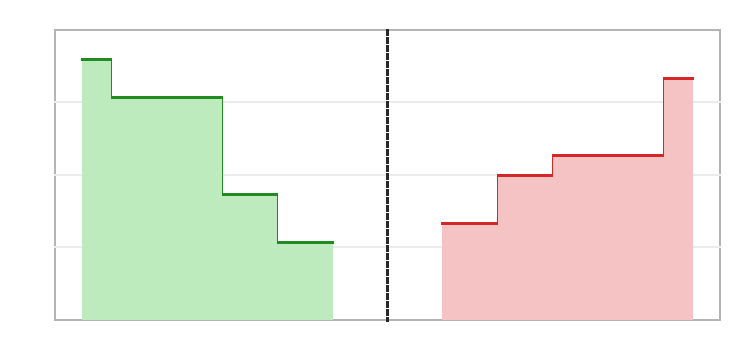

In [24]:
import matplotlib.pyplot as plt

def plot_depth_chart(lob):
    """
    Plots the depth chart for the given order book.
    """
    # Step 1: Build bid data (prices and cumulative qty)
    bid_prices = []
    bid_cumulative = []
    cum_bid = 0
    for o in sorted(lob.bids, key=lambda x: x['price'], reverse=True):
        cum_bid += remaining_qty(o)
        bid_prices.append(o['price'])
        bid_cumulative.append(cum_bid)

    # Step 2: Build ask data
    ask_prices = []
    ask_cumulative = []
    cum_ask = 0
    for o in sorted(lob.asks, key=lambda x: x['price']):
        cum_ask += remaining_qty(o)
        ask_prices.append(o['price'])
        ask_cumulative.append(cum_ask)

    # Step 3: Plot
    fig, ax = plt.subplots(figsize=(10, 5))
    if bid_prices:
        ax.step(bid_prices, bid_cumulative, where='post', color='green', lw=2, label='Bids (Cumulative Qty)')
        ax.fill_between(bid_prices, bid_cumulative, step='post', color='green', alpha=0.3)
    if ask_prices:
        ax.step(ask_prices, ask_cumulative, where='post', color='red', lw=2, label='Asks (Cumulative Qty)')
        ax.fill_between(ask_prices, ask_cumulative, step='post', color='red', alpha=0.3)

    mid = lob.mid_price()
    if mid is not None:
        ax.axvline(mid, color='black', linestyle='--', lw=1.2, label=f'Mid Price (${mid:.2f})')

    ax.set_xlabel('Price ($)')
    ax.set_ylabel('Cumulative Quantity (Shares)')
    ax.set_title('Limit Order Book — Market Depth Chart')
    ax.legend()
    ax.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()

plot_depth_chart(lob_demo)

### Q4.3 — How does the spread change after a large trade? (7 marks)

When a large aggressive order sweeps through multiple price levels, it **widens the spread** and **changes the mid price**.

**Task:**
1. Record the `spread` and `mid_price` of `lob_demo` **before** the trade.
2. Submit an aggressive buy order for **1,200 shares at $103** using `match_order`.
3. Record the `spread` and `mid_price` **after** the trade.
4. Compute and print: VWAP of the fill, slippage in bps, how much the spread changed, how much the mid price moved.
5. Display the book before and after (use `lob_demo.display()`).
6. Answer in the markdown cell: what happened to the book and why?

>  **Hint:** Use the functions you already wrote — `calculate_vwap`, `match_order`, `spread()`, `mid_price()`, `display()`.

In [25]:
print('=== BEFORE ===')
lob_demo.display()
spread_before = lob_demo.spread()
mid_before    = lob_demo.mid_price()
expected_ask  = lob_demo.best_ask()

# Submit the large aggressive buy
big_buy = create_order('big_buy', 'BID', 1200, 103.0)
trades  = lob_demo.match_order(big_buy)

print('\n=== AFTER ===')
lob_demo.display()
spread_after = lob_demo.spread()
mid_after    = lob_demo.mid_price()

# Compute metrics
vwap_fill     = calculate_vwap(trades)
slippage_bps  = ((vwap_fill - expected_ask) / expected_ask) * 10000
spread_change = spread_after - spread_before
mid_change    = mid_after - mid_before

print(f'\nVWAP of fill:             ${vwap_fill:.2f}')
print(f'Slippage:                 {slippage_bps:.2f} bps')
print(f'Spread before → after:    {spread_before} → {spread_after} (change: +{spread_change:.1f})')
print(f'Mid price before → after: {mid_before} → {mid_after} (change: +{mid_change:.1f})')

=== BEFORE ===
========= ORDER BOOK =========
        ASKS (Sellers)
  Price    |   Qty
  105.0    |   800
  103.0    |   200
  102.0    |   500
  101.0    |  1000
--------- Spread: 2.0 ---------
        BIDS (Buyers)
  Price    |   Qty
  99.0     |   800
  98.0     |   500
  97.0     |  1000
  95.0     |   400

=== AFTER ===
========= ORDER BOOK =========
        ASKS (Sellers)
  Price    |   Qty
  105.0    |   800
  103.0    |   200
  102.0    |   300
--------- Spread: 3.0 ---------
        BIDS (Buyers)
  Price    |   Qty
  99.0     |   800
  98.0     |   500
  97.0     |  1000
  95.0     |   400

VWAP of fill:             $101.17
Slippage:                 16.50 bps
Spread before → after:    2.0 → 3.0 (change: +1.0)
Mid price before → after: 100.0 → 100.5 (change: +0.5)


**Q4.3 — Analysis:** *(What happened to the spread and mid price? Why did they move? What does this tell you about the concept of "price impact"?)*

**Answer:**
- **What happened to the book:** Before the trade, the best bid was $\$99.0$ and the best ask was $\$101.0$ (with 1,000 shares resting at $\$101.0$), giving a **spread of $\$2.0$** and a **mid price of $\$100.0$**. The aggressive buy order for **1,200 shares at $\$103.0$** completely consumed all 1,000 shares at the $\$101.0$ ask level and then took 200 of the 500 shares resting at $\$102.0$ ($\text{VWAP} = \$101.17$, slippage $= 16.50\text{ bps}$). Because the entire $\$101.0$ ask level was wiped out, the new best ask moved up to $\$102.0$ (with 300 shares remaining), while the best bid stayed at $\$99.0$. Consequently:
  - The **spread widened** from $\$2.0$ to **$\$3.0$** ($+\$1.0$).
  - The **mid price moved up** from $\$100.0$ to **$\$100.5$** ($+\$0.5$).
- **What this tells us about Price Impact:** Aggressive orders do not merely observe the market price — they **change** it by consuming liquidity at the best quotes. When a buy order is larger than the quantity available at the best ask, it depletes that price level and shifts the best ask upward, mechanically increasing the mid-price and widening the spread (until new limit orders arrive to replenish the book). This upward shift in quoted prices caused by aggressive buying (or downward shift from aggressive selling) is the micro-structural mechanism of **market impact**.

---
## Section 5 — Thinking Like a Trader (15 marks)

This section has no coding template — you design the solution yourself.

These questions test whether you understand the *why* behind the mechanics you built.

**a)** Why is a limit order book split into two sides (bids and asks), and why are bids sorted descending by price while asks are sorted ascending?

**Answer 5.1a:**

- **Why split into two sides (Bids vs. Asks):** Buyers and sellers have opposite objectives — buyers want to purchase at or *below* their limit price, while sellers want to sell at or *above* their limit price. Separating resting buy orders (bids) from resting sell orders (asks) cleanly partitions supply and demand and makes it immediately obvious where the market's buying interest meets selling interest.
- **Why Bids are sorted descending while Asks are sorted ascending:** An exchange always matches the **most competitive (best) prices first** (Price Priority):
  - For **buyers (bids)**, the most competitive buyer is the one willing to pay the **highest** price, so sorting bids **descending** puts the highest bid (`best_bid`) at index `0` (top of book).
  - For **sellers (asks)**, the most competitive seller is the one willing to accept the **lowest** price, so sorting asks **ascending** puts the lowest ask (`best_ask`) at index `0` (top of book).
  - This guarantees $O(1)$ access to the top-of-book prices on both sides and allows the matching engine to sweep outward from the most competitive price levels.

**b)** Trader A and Trader B both place limit buy orders for 500 shares at $100. Trader A submits at 9:00:01 AM and Trader B at 9:00:02 AM. A sell order for 300 shares arrives and matches. Who gets filled, and for how much? What is the remaining state of the book?

**Answer 5.1b:**

- **Who gets filled and for how much:** **Trader A** gets filled for **300 shares at $\$100$**, and **Trader B gets 0 shares filled**. Because both Trader A and Trader B quoted the exact same price ($\$100$), the exchange breaks the tie using **Time Priority (FIFO — First-In, First-Out)**: Trader A submitted earlier (9:00:01 AM vs. 9:00:02 AM), so Trader A stands at the front of the queue at the $\$100$ price level.
- **Remaining state of the book:**
  - **Trader A's order** remains at the front of the $\$100$ bid queue with **200 shares remaining** (`quantity = 500`, `filled_qty = 300`).
  - **Trader B's order** remains behind Trader A at the $\$100$ bid level with all **500 shares remaining** (`quantity = 500`, `filled_qty = 0`).
  - Total bid liquidity resting at $\$100$ is now **700 shares** (200 from Trader A + 500 from Trader B).

**c)** A market maker is simultaneously quoting a bid at $99 and an ask at $101 (a spread of $2). A buyer hits their ask and a seller hits their bid in quick succession. Both trades are for 100 shares. Ignoring fees, what is the market maker's profit from this? What risk does the market maker face if they can't trade both sides?

**Answer 5.1c:**

- **Market maker's profit:** The market maker sells 100 shares at the ask of $\$101$ (receiving $\$10,100$ in cash) and buys 100 shares at the bid of $\$99$ (paying $\$9,900$ in cash). Their net inventory returns to **0 shares** (flat), and they earn the **bid-ask spread of $\$2$ per share** across 100 shares:
  $$\text{Profit} = (\$101 - \$99) \times 100 = \mathbf{\$200}$$
- **Risks if they can't trade both sides:**
  1. **Inventory Risk (Price Volatility Risk):** If only one side is filled (e.g., a seller hits their bid at $\$99$, leaving the market maker long 100 shares), the market maker holds unhedged inventory. If the fundamental mid-price drops below $\$99$ before they can sell, they suffer mark-to-market losses.
  2. **Adverse Selection (Informed Flow Risk):** Often, the *reason* only one side gets hit is that an informed trader knows the true asset value has already moved (e.g., bad news arrives, so everyone sells to the market maker's $\$99$ bid while nobody lifts their $\$101$ ask). The market maker accumulates a losing position strictly on the wrong side of a market move.

### Q5.2 — Fee Calculator (4 marks)

Exchanges charge fees on trades:
- **Maker fee** — paid by the **passive** order (the one resting in the book)
- **Taker fee** — paid by the **aggressive** order (the one that crossed the spread)

Sometimes the maker gets a **rebate** (negative fee — the exchange *pays* them for providing liquidity).

**Scenario:** 50,000 shares traded at $200. Taker fee = 0.07% (7 bps). Maker rebate = 0.025% (2.5 bps).

Write code to compute:
1. The total value of the trade
2. The fee paid by the taker
3. The rebate received by the maker
4. The net cost to the taker (price paid + fee)
5. The net revenue to the maker (price received − fee, i.e., + rebate)

>  **Hint:** `fee = trade_value * (fee_percent / 100)`

In [26]:
quantity         = 50_000
price            = 200.0
taker_fee_pct    = 0.07    # percent
maker_rebate_pct = 0.025   # percent

trade_value       = quantity * price
taker_fee         = trade_value * (taker_fee_pct / 100)
maker_rebate      = trade_value * (maker_rebate_pct / 100)
net_cost_taker    = trade_value + taker_fee
net_revenue_maker = trade_value + maker_rebate

print(f'1. Trade value:           ${trade_value:,.0f}')
print(f'2. Taker pays fee:        ${taker_fee:,.0f}')
print(f'3. Maker receives rebate: ${maker_rebate:,.0f}')
print(f'4. Net cost to taker:     ${net_cost_taker:,.0f}')
print(f'5. Net revenue to maker:  ${net_revenue_maker:,.0f}')

1. Trade value:           $10,000,000
2. Taker pays fee:        $7,000
3. Maker receives rebate: $2,500
4. Net cost to taker:     $10,007,000
5. Net revenue to maker:  $10,002,500


### Q5.3 — Design Challenge (5 marks)

Your current `OrderBook` stores orders as a flat list. As the number of orders grows into the thousands (like on a real exchange), the matching in Q3.2 gets slower because searching a list takes longer.

**Question (written answer):** Suggest a better data structure for storing orders in each side of the book. Explain:
- What structure you would use (you can describe it in plain English — no need to implement it)
- Why it would be faster for matching
- What operation would become slightly more complex with your new structure

>  **Hint:** Think about what operations you do most often: finding the best price, iterating in price order, removing a specific order by ID. Which Python data structures are fast at which operations? (Think: dictionaries, sorted lists, heaps...)

**Answer 5.3:**

### Proposed Data Structure: Hybrid **Sorted Price Map + Doubly-Linked FIFO Queues + Order-ID Hash Map**

Instead of a single flat list sorted on every insertion ($O(N \log N)$) and scanned linearly on every cancellation ($O(N)$), production matching engines (e.g., NASDAQ ITCH / LMAX) combine **three coordinated structures**:

1. **Sorted Price-Level Structure (Balanced BST / Skip List / Heap + Price Hash Map):**
   - Stores distinct **price levels** in sorted order (descending for bids, ascending for asks). In Python, this can be a `SortedDict` (from `sortedcontainers`) or a min/max `heapq` paired with a dictionary `{price: PriceLevelQueue}`.
2. **FIFO Queue at Each Price Level (Doubly-Linked List / `collections.deque`):**
   - Each price level points to a doubly-linked list of orders resting at that exact price, ordered by arrival time (preserving strict FIFO time priority).
3. **Order Lookup Dictionary (`order_map = {order_id: order_node}`):**
   - A hash map (`dict`) mapping every active `order_id` directly to its node in the doubly-linked list.

---

### Why It Is Faster for Matching and Book Operations

| Operation | Flat List (`list`) | Hybrid LOB Structure | Why It's Faster |
|---|---|---|---|
| **Best Bid / Ask (`best_bid`, `best_ask`)** | $O(1)$ | **$O(1)$** | Pointer to the root/extremum of the sorted price map gives the best level immediately. |
| **Add Order (`add_order`)** | $O(N \log N)$ (re-sorting) | **$O(1)$** (existing price) or **$O(\log P)$** (new price) | Appending to an existing price level's FIFO queue is $O(1)$; inserting a new price level takes $O(\log P)$ where $P \ll N$ is the number of distinct prices. |
| **Match Order (`match_order`)** | $O(N)$ per `pop(0)` shift | **$O(1)$ per filled order** | Popping the head of a doubly-linked list at the best price level is strictly $O(1)$ (unlike `list.pop(0)` which shifts all $N-1$ elements in memory). |
| **Cancel Order (`cancel_order`)** | $O(N)$ linear scan | **$O(1)$** | `order_map[order_id]` locates the node in $O(1)$ time, and unlinking a node from a doubly-linked list takes $O(1)$ pointer updates. |

---

### What Becomes Slightly More Complex

- **Synchronizing Multiple Structures & Memory Overhead:** Every add, fill, or cancel must keep **three** structures in sync (`order_map`, the price level's doubly-linked list, and the sorted price tree/heap). Specifically, when the last order at a price level is filled or cancelled, the empty price level must be cleanly pruned from the sorted price tree/heap (or lazily deleted from a heap), which adds bookkeeping complexity and extra pointer memory compared to a single flat list.